# Credit scoring — white-box model (logistic regression)

Data: Kaggle Playground S5E11 (loan payback). We model the probability of **default** (`default = 1 - loan_paid_back`), the usual convention in credit scoring — coefficients then read as risk factors. AUC is unchanged by this choice, so results stay directly comparable with the other two models.

Evaluation protocol :
- shared test set `test_eval_20k.csv` (20,000 rows), removed from our training data
- economic performance: repaid loan earns `loan_amount * interest_rate / 100`, defaulted loan costs `0.60 * loan_amount`, rejected loan = 0
- approval threshold tuned on a validation split from our own training data, never on the shared test set
- sensitive attributes for the fairness audit: gender, marital_status, employment_status, education_level

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, roc_curve, precision_recall_curve,
                             average_precision_score, brier_score_loss, confusion_matrix)
from sklearn.calibration import calibration_curve

SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['axes.grid'] = True

## 1. Data

We drop the 20k shared-test ids from the training pool.

In [2]:
full = pd.read_csv('data/train.csv')
test = pd.read_csv('data/test_eval_20k.csv')

train = full[~full['id'].isin(test['id'])].copy()
print(f"training pool: {train.shape[0]:,} rows | shared test: {test.shape[0]:,} rows")
print(f"repayment rate — train: {train['loan_paid_back'].mean():.4f} | test: {test['loan_paid_back'].mean():.4f}")
train.head()

training pool: 573,994 rows | shared test: 20,000 rows
repayment rate — train: 0.7988 | test: 0.7988


,id,annual_income,debt_to_income_ratio,credit_score,loan_amount,interest_rate,gender,marital_status,education_level,employment_status,loan_purpose,grade_subgrade,loan_paid_back
0,0,29367.99,0.084,736,2528.42,13.67,Female,Single,High School,Self-employed,Other,C3,1.0
1,1,22108.02,0.166,636,4593.10,12.92,Male,Married,Master's,Employed,Debt consolidation,D3,0.0
2,2,49566.20,0.097,694,17005.15,9.76,Male,Single,High School,Employed,Debt consolidation,C5,1.0
3,3,46858.25,0.065,533,4682.48,16.10,Female,Single,High School,Employed,Debt consolidation,F1,1.0
4,4,25496.70,0.053,665,12184.43,10.21,Male,Married,High School,Employed,Other,D1,1.0


## 2. Quick EDA

### 2.1 Numeric features by outcome

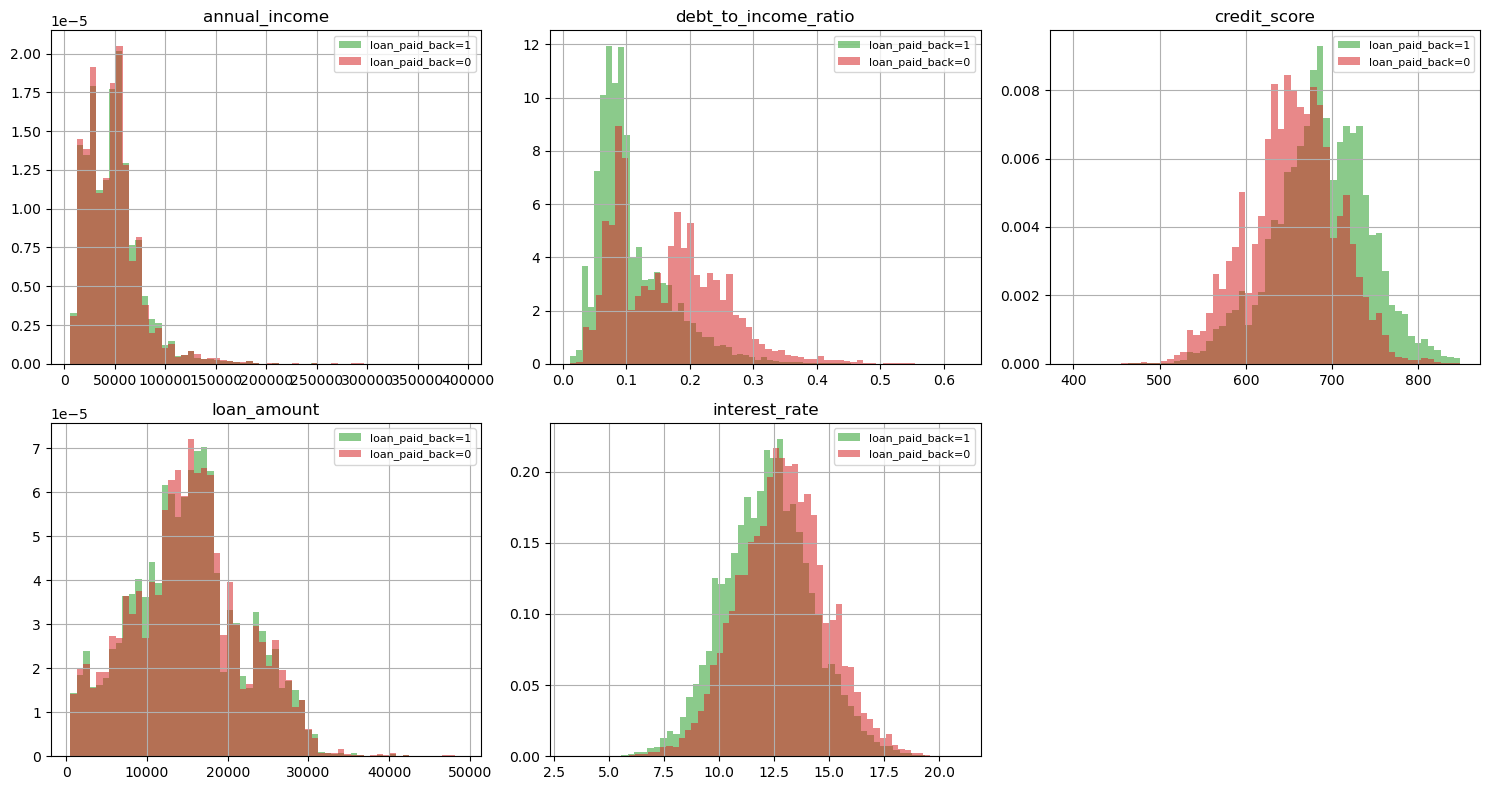

,annual_income,debt_to_income_ratio,credit_score,loan_amount,interest_rate
loan_paid_back,,,,,
0.0,47872.723653,0.166572,655.045325,15075.552065,12.883371
1.0,48306.253759,0.109124,687.439643,15007.846193,12.224003


In [3]:
TARGET = 'loan_paid_back'
NUM_RAW = ['annual_income', 'debt_to_income_ratio', 'credit_score', 'loan_amount', 'interest_rate']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), NUM_RAW):
    for cls, color in [(1, 'tab:green'), (0, 'tab:red')]:
        ax.hist(train.loc[train[TARGET] == cls, col], bins=60, alpha=0.55,
                density=True, color=color, label=f'{TARGET}={cls}')
    ax.set_title(col); ax.legend(fontsize=8)
axes.ravel()[-1].axis('off')
plt.tight_layout(); plt.show()

train.groupby(TARGET)[NUM_RAW].mean()

Defaults sit where you would expect them: lower credit score, higher interest rate, higher debt-to-income. Income and loan amount barely separate the two classes on their own.

### 2.2 Repayment rate by category

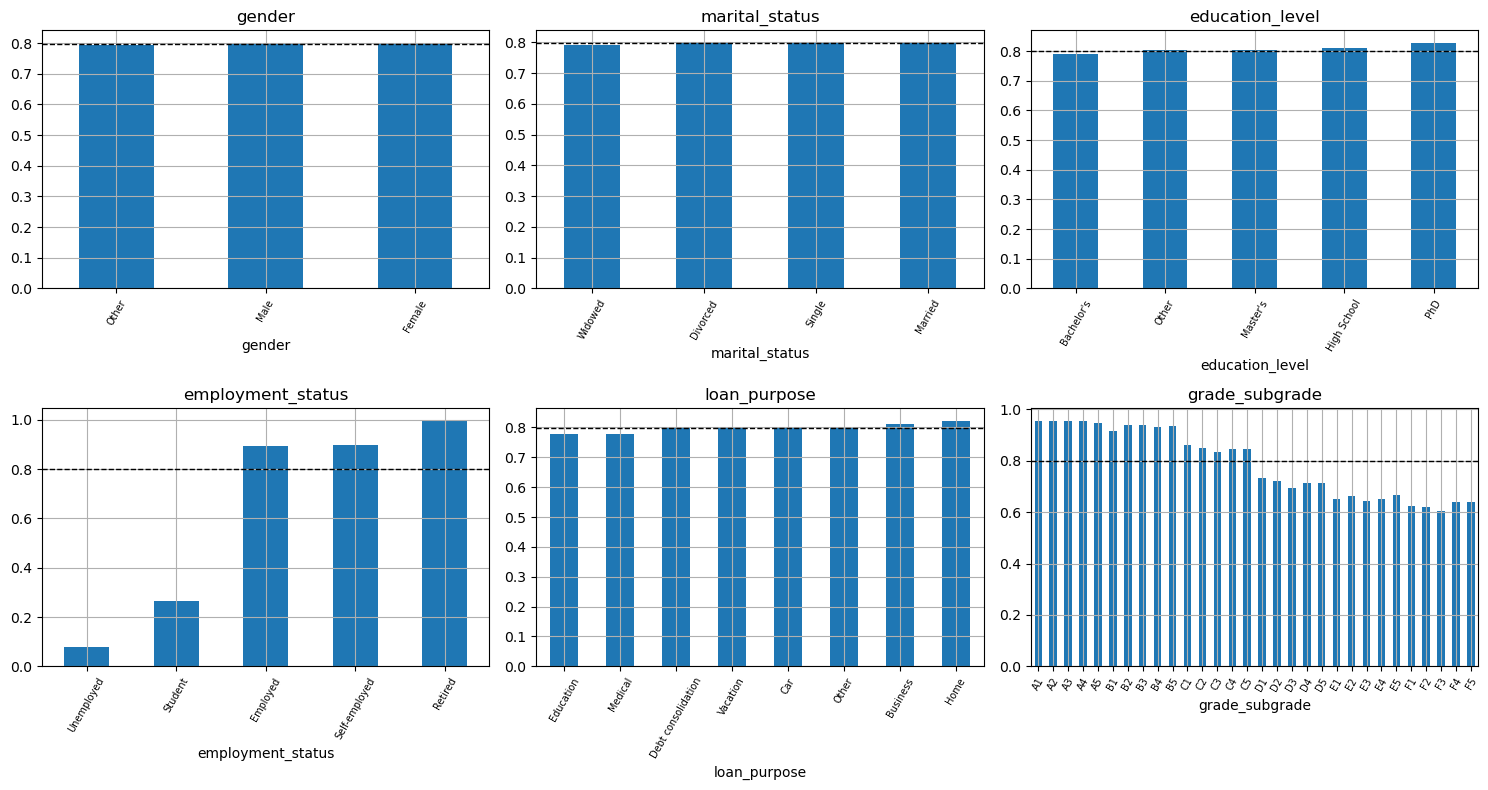

In [4]:
CAT_RAW = ['gender', 'marital_status', 'education_level', 'employment_status', 'loan_purpose']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), CAT_RAW + ['grade_subgrade']):
    rate = train.groupby(col)[TARGET].mean()
    rate = rate.sort_index() if col == 'grade_subgrade' else rate.sort_values()
    rate.plot(kind='bar', ax=ax, color='tab:blue')
    ax.axhline(train[TARGET].mean(), color='k', ls='--', lw=1)
    ax.set_title(col); ax.set_ylabel(''); ax.tick_params(axis='x', labelsize=7, rotation=60)
plt.tight_layout(); plt.show()

Two things stand out. Repayment decreases almost monotonically from A1 to F5, which justifies encoding `grade_subgrade` as a single ordinal variable (0 to 29) rather than 30 dummies — one coefficient, direct reading. And `employment_status` separates the classes far more than anything else (retired people almost never default here, unemployed people mostly do). The gender/marital gaps in raw repayment rates are tiny, but raw rates say nothing about the fairness of the model's *decisions* — that's section 7.

### 2.3 Correlations

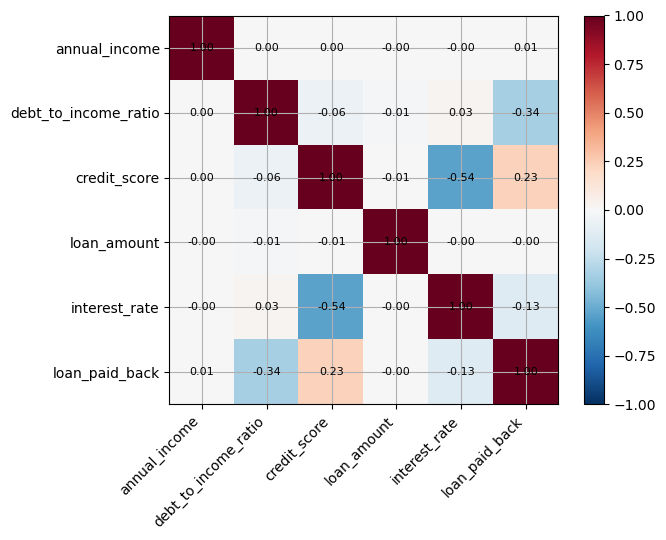

In [5]:
corr = train[NUM_RAW + [TARGET]].corr()
fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha='right')
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)
plt.colorbar(im); plt.tight_layout(); plt.show()

`interest_rate` and `credit_score` are strongly (negatively) correlated — the rate already prices the risk. Worth keeping in mind when we read individual coefficients later: with correlated regressors, conditional effects can differ from marginal ones, and signs can look surprising.

## 3. Preprocessing

Choices, and why:
- target: `default = 1 - loan_paid_back`
- `grade_subgrade` -> ordinal `grade_ord` (A1=0 ... F5=29), justified by 2.2
- numeric features standardized (fit on train only) so coefficients are comparable: each one is the effect of a +1 SD move
- categoricals one-hot encoded with a dropped reference level
- `gender` and `marital_status` are **left out of the model**. Using them in credit underwriting is prohibited (direct discrimination); we keep them aside for the fairness audit. `employment_status` and `education_level` stay in: they are legitimate creditworthiness variables, and we audit fairness on them too rather than pretending the question doesn't exist.
- 80/20 stratified split of the training pool; the validation part is used to pick the approval threshold and to sanity-check metrics. Final evaluation happens on the shared 20k test set only.

In [6]:
def prep(df):
    df = df.copy()
    df['default'] = (1 - df['loan_paid_back']).astype(int)
    letter = df['grade_subgrade'].str[0].map({l: i for i, l in enumerate('ABCDEF')})
    df['grade_ord'] = letter * 5 + df['grade_subgrade'].str[1].astype(int) - 1
    return df

train = prep(train)
test = prep(test)

NUM = NUM_RAW + ['grade_ord']
CAT = ['education_level', 'employment_status', 'loan_purpose']   # no gender / marital_status
SENSITIVE = ['gender', 'marital_status', 'employment_status', 'education_level']

X_all = pd.get_dummies(train[NUM + CAT], columns=CAT, drop_first=True, dtype=float)
y_all = train['default'].values
X_test = pd.get_dummies(test[NUM + CAT], columns=CAT, drop_first=True, dtype=float)
X_test = X_test.reindex(columns=X_all.columns, fill_value=0.0)
y_test = test['default'].values

X_tr, X_val, y_tr, y_val, idx_tr, idx_val = train_test_split(
    X_all, y_all, train.index, test_size=0.20, stratify=y_all, random_state=SEED)

mu, sd = X_tr[NUM].mean(), X_tr[NUM].std()
for Z in (X_tr, X_val, X_test):
    Z[NUM] = (Z[NUM] - mu) / sd

print(f"train {X_tr.shape} | validation {X_val.shape} | shared test {X_test.shape}")

train (459195, 21) | validation (114799, 21) | shared test (20000, 21)


## 4. Model

We fit the logit with statsmodels rather than sklearn: for a white-box model we want the full inferential output (standard errors, p-values), not just point estimates. No penalty — with ~459k observations for 22 parameters, regularization has nothing to do here (we checked: AUC is flat in C over [0.01, 10]).

In [7]:
X_tr_sm = sm.add_constant(X_tr.astype(float))
X_val_sm = sm.add_constant(X_val.astype(float))
X_test_sm = sm.add_constant(X_test.astype(float))

logit = sm.Logit(y_tr, X_tr_sm).fit(disp=0, maxiter=200)
p_val = logit.predict(X_val_sm).values
p_test = logit.predict(X_test_sm).values

coef_table = pd.DataFrame({'coef': logit.params, 'std_err': logit.bse,
                           'p_value': logit.pvalues, 'odds_ratio': np.exp(logit.params)})
coef_table.reindex(coef_table.coef.abs().sort_values(ascending=False).index).round(4)

,coef,std_err,p_value,odds_ratio
employment_status_Unemployed,5.0058,0.0198,0.0000,149.2786
employment_status_Retired,-3.8583,0.1686,0.0000,0.0211
employment_status_Student,3.4065,0.0276,0.0000,30.1587
const,-2.5787,0.0234,0.0000,0.0759
credit_score,-0.8752,0.0138,0.0000,0.4168
debt_to_income_ratio,0.8659,0.0049,0.0000,2.3771
education_level_PhD,-0.1937,0.0420,0.0000,0.8239
loan_purpose_Medical,0.1518,0.0348,0.0000,1.1640
loan_purpose_Education,0.1496,0.0306,0.0000,1.1614
education_level_High School,-0.1209,0.0125,0.0000,0.8862


In [8]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
Xn = X_tr[NUM].values
vif = pd.Series([variance_inflation_factor(Xn, i) for i in range(len(NUM))], index=NUM)
print(vif.round(2))  # interest_rate / credit_score / grade_ord carry overlapping information

annual_income           1.00
debt_to_income_ratio    1.00
credit_score            6.08
loan_amount             1.00
interest_rate           1.41
grade_ord               5.67
dtype: float64


## 5. Predictive performance

### 5.1 Statistical, on the shared test set

AUC = 0.9061 (Gini = 0.8121) | AP = 0.8077 | Brier = 0.0785
(validation AUC = 0.9103 — no train/test gap, as expected for a linear model)


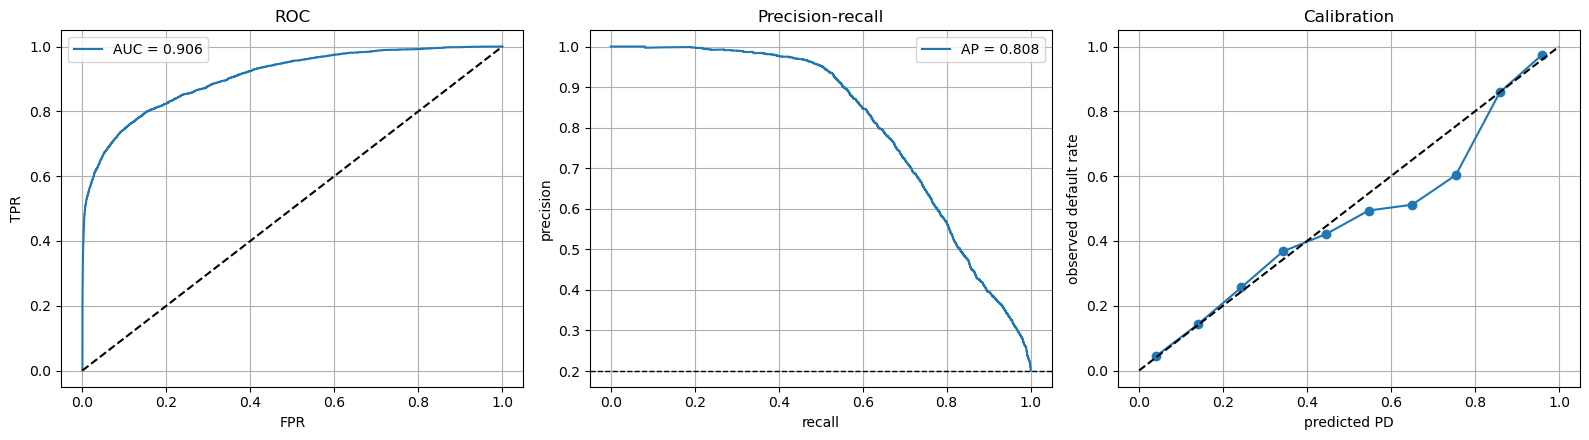

In [9]:
auc = roc_auc_score(y_test, p_test)
ap = average_precision_score(y_test, p_test)
brier = brier_score_loss(y_test, p_test)
print(f"AUC = {auc:.4f} (Gini = {2*auc-1:.4f}) | AP = {ap:.4f} | Brier = {brier:.4f}")
print(f"(validation AUC = {roc_auc_score(y_val, p_val):.4f} — no train/test gap, as expected for a linear model)")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
fpr, tpr, _ = roc_curve(y_test, p_test)
axes[0].plot(fpr, tpr, label=f'AUC = {auc:.3f}'); axes[0].plot([0,1],[0,1],'k--')
axes[0].set_xlabel('FPR'); axes[0].set_ylabel('TPR'); axes[0].set_title('ROC'); axes[0].legend()

prec, rec, _ = precision_recall_curve(y_test, p_test)
axes[1].plot(rec, prec, label=f'AP = {ap:.3f}')
axes[1].axhline(y_test.mean(), color='k', ls='--', lw=1)
axes[1].set_xlabel('recall'); axes[1].set_ylabel('precision'); axes[1].set_title('Precision-recall'); axes[1].legend()

frac_pos, mean_pred = calibration_curve(y_test, p_test, n_bins=10)
axes[2].plot(mean_pred, frac_pos, 'o-'); axes[2].plot([0,1],[0,1],'k--')
axes[2].set_xlabel('predicted PD'); axes[2].set_ylabel('observed default rate'); axes[2].set_title('Calibration')
plt.tight_layout(); plt.show()

The calibration curve sits on the diagonal without any recalibration. This matters more than a few AUC points in a banking context: the PD feeds pricing and provisioning, not just an approve/reject decision. Tree ensembles typically need Platt scaling or isotonic regression to get there — worth raising in the final model comparison.

### 5.2 Economic performance

Threshold is swept on the **validation** sample; the shared test set is only touched once, with the frozen threshold. A 0.5 cutoff has no business meaning here anyway: a defaulted loan costs roughly four times what an average good loan earns in interest, so the profit-maximizing rule is much more conservative.

threshold tuned on validation: tau* = 0.16
P&L on shared test  @ tau*   :  16.72 M$   (approval rate 71.7%)
P&L on shared test  @ 0.5    :  13.66 M$
P&L approving everyone       :  -6.88 M$


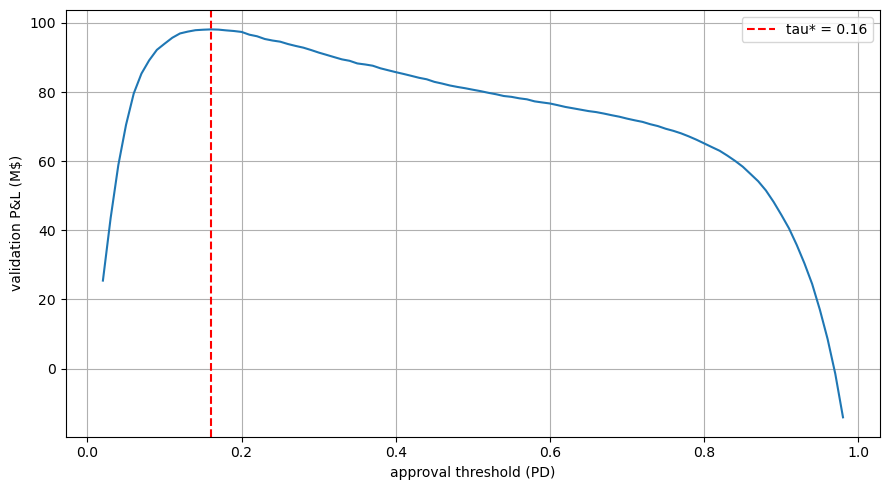

In [10]:
val_raw = train.loc[idx_val]

def profit(p, y, amounts, rates, tau):
    approve = p < tau                      # approve when predicted PD below tau
    gain = (amounts * rates / 100 * ((y == 0) & approve)).sum()
    loss = (amounts * 0.60 * ((y == 1) & approve)).sum()
    return gain - loss

taus = np.arange(0.02, 0.99, 0.01)
pnl_val = np.array([profit(p_val, y_val, val_raw['loan_amount'].values,
                           val_raw['interest_rate'].values, t) for t in taus])
TAU = round(taus[pnl_val.argmax()], 2)

pnl_test = profit(p_test, y_test, test['loan_amount'].values, test['interest_rate'].values, TAU)
pnl_naive = profit(p_test, y_test, test['loan_amount'].values, test['interest_rate'].values, 0.5)
pnl_all = profit(p_test, y_test, test['loan_amount'].values, test['interest_rate'].values, 1.01)

print(f"threshold tuned on validation: tau* = {TAU}")
print(f"P&L on shared test  @ tau*   : {pnl_test/1e6:6.2f} M$   (approval rate {(p_test<TAU).mean():.1%})")
print(f"P&L on shared test  @ 0.5    : {pnl_naive/1e6:6.2f} M$")
print(f"P&L approving everyone       : {pnl_all/1e6:6.2f} M$")

plt.plot(taus, pnl_val / 1e6)
plt.axvline(TAU, ls='--', c='r', label=f'tau* = {TAU}')
plt.xlabel('approval threshold (PD)'); plt.ylabel('validation P&L (M$)')
plt.legend(); plt.tight_layout()
plt.savefig('fig_pnl.png', dpi=120); plt.show()

The scoring model turns a losing book (approving everyone destroys value) into a profitable one, and tuning the threshold adds another ~20% of profit over the naive 0.5 rule. The choice of threshold matters about as much as the choice of model — a point we want to keep for the final recommendation.

## 6. Interpretability

This is where the white-box earns its keep: the score *is* a weighted sum, so explanations are exact, not post-hoc approximations.

### 6.1 Global drivers

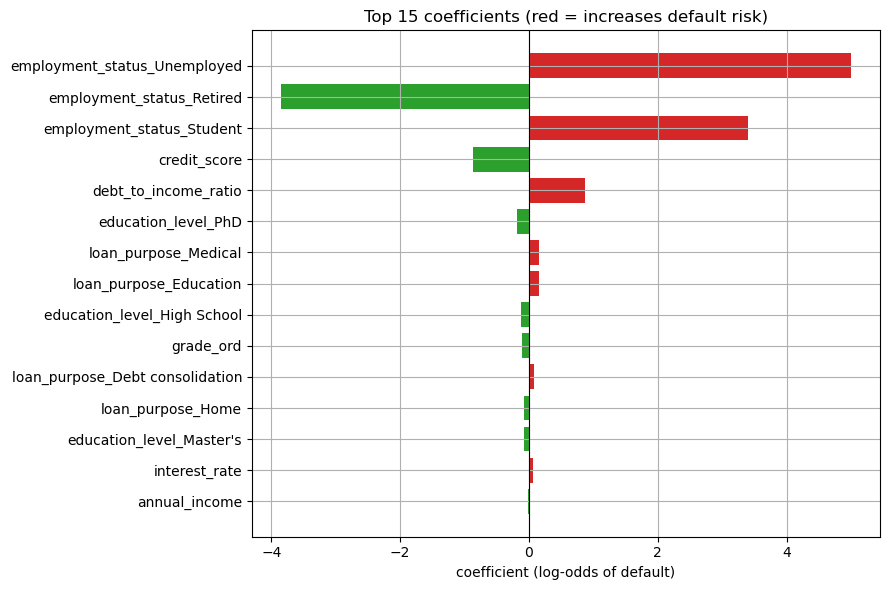

In [11]:
top = coef_table.drop(index='const')
top = top.reindex(top.coef.abs().sort_values().index).tail(15)
colors = ['tab:red' if c > 0 else 'tab:green' for c in top['coef']]   # red = raises PD
plt.figure(figsize=(9, 6))
plt.barh(top.index, top['coef'], color=colors)
plt.axvline(0, color='k', lw=0.8)
plt.title('Top 15 coefficients (red = increases default risk)')
plt.xlabel('coefficient (log-odds of default)')
plt.tight_layout(); plt.show()

Employment status dominates by an order of magnitude: relative to employed borrowers, being unemployed multiplies the odds of default by ~150, being a student by ~29, while retirees almost never default (OR ~0.02). Then come `credit_score` and `debt_to_income_ratio` (roughly symmetric effects, OR ~0.41 and ~2.38 per SD). `loan_amount` is not significant.

One coefficient needs to be defended rather than hidden: `grade_ord` comes out *negative* (better grades supposedly riskier), which contradicts the raw monotonic pattern of section 2.2. This is a collinearity artifact — `credit_score` and `interest_rate` already carry the grade information, so the conditional effect flips sign. It's a textbook illustration of why coefficient signs shouldn't be read in isolation when regressors are correlated, and it doesn't affect predictions.

### 6.2 Marginal effects

Logit coefficients live on the log-odds scale. To speak in probability points we compute average marginal effects (AME, averaged over individuals) and marginal effects at the mean (MEM). Features are standardized, so effects read per +1 SD.

In [12]:
w_ame = (p_test * (1 - p_test)).mean()
xbar = X_test_sm.mean().values
p_at_mean = 1 / (1 + np.exp(-(xbar @ logit.params.values)))
w_mem = p_at_mean * (1 - p_at_mean)

me = pd.DataFrame({
    'AME (pp per +1 SD)': (w_ame * logit.params[NUM] * 100).round(2),
    'MEM (pp per +1 SD)': (w_mem * logit.params[NUM] * 100).round(2)})
print(f"mean of p(1-p) = {w_ame:.4f} ; PD at the mean borrower = {p_at_mean:.4f}")
me

mean of p(1-p) = 0.0757 ; PD at the mean borrower = 0.1102


,AME (pp per +1 SD),MEM (pp per +1 SD)
annual_income,-0.14,-0.18
debt_to_income_ratio,6.55,8.49
credit_score,-6.62,-8.58
loan_amount,-0.03,-0.04
interest_rate,0.43,0.55
grade_ord,-0.85,-1.11


One SD of `debt_to_income_ratio` (~0.07) moves the default probability by about +6.5 points on average; one SD of `credit_score` (~65 points) by about -6.7. MEM exceeds AME because the average borrower sits near the steep part of the sigmoid, while the population average of p(1-p) is dragged down by the many borrowers whose PD is close to 0.

### 6.3 Explaining one decision

Each decision decomposes exactly: log-odds(x_i) - log-odds(x_mean) = sum_j beta_j (x_ij - x_mean_j). This is the kind of statement a bank must be able to produce for a rejected applicant (GDPR art. 22 / AI Act — credit scoring is a high-risk system).

In [13]:
def explain(i, top_k=6):
    contrib = (X_test_sm.iloc[i].values - xbar) * logit.params.values
    expl = pd.Series(contrib, index=X_test_sm.columns).sort_values(key=abs, ascending=False)
    decision = 'REJECTED' if p_test[i] >= TAU else 'APPROVED'
    print(f"applicant id={test.iloc[i]['id']} — predicted PD {p_test[i]:.1%} "
          f"(portfolio mean {p_test.mean():.1%}) -> {decision}")
    print(expl.head(top_k).round(3).to_string(), '\n')

explain(int(np.argmax(p_test)))   # riskiest applicant in the test set
explain(int(np.argmin(p_test)))  # safest

applicant id=232931 — predicted PD 100.0% (portfolio mean 20.0%) -> REJECTED
debt_to_income_ratio            4.510
employment_status_Unemployed    4.490
credit_score                    1.606
grade_ord                      -0.331
interest_rate                   0.140
employment_status_Retired       0.103 

applicant id=315312 — predicted PD 0.0% (portfolio mean 20.0%) -> APPROVED
employment_status_Retired      -3.755
credit_score                   -2.593
debt_to_income_ratio           -0.646
employment_status_Unemployed   -0.516
grade_ord                       0.286
interest_rate                  -0.134 



## 7. Stability

A model that tells a different story on every resample is not deployable, whatever its AUC. Three complementary checks.

### 7.1 Cross-validated performance

In [14]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
skl = LogisticRegression(C=np.inf, max_iter=1000)
cv_auc = cross_val_score(skl, X_tr.values.astype(float), y_tr, cv=cv, scoring='roc_auc', n_jobs=1)
print('AUC per fold:', np.round(cv_auc, 5))
print(f"mean {cv_auc.mean():.5f} | sd {cv_auc.std():.5f}")

AUC per fold: [0.91006 0.90969 0.91037 0.91092 0.91074]
mean 0.91035 | sd 0.00045


### 7.2 Bootstrap of the coefficients

20 full-size bootstrap resamples of the training set. We look at the L2 distance between coefficient vectors, and at sign stability — does the model keep saying the same thing?

In [15]:
B = 20
Xv = X_tr.values.astype(float)
boot = []
for b in range(B):
    idx = rng.choice(len(y_tr), len(y_tr), replace=True)
    m = LogisticRegression(C=np.inf, max_iter=500).fit(Xv[idx], y_tr[idx])
    boot.append(np.r_[m.intercept_, m.coef_.ravel()])
boot = np.array(boot)

theta = logit.params.values
names = ['const'] + list(X_tr.columns)
d_full = np.linalg.norm(boot - theta, axis=1)
d_pair = [np.linalg.norm(boot[a] - boot[b]) for a in range(B) for b in range(a+1, B)]
sign_stab = (np.sign(boot) == np.sign(theta)).mean(axis=0)

print(f"||theta|| = {np.linalg.norm(theta):.2f}")
print(f"mean distance to full-sample fit : {d_full.mean():.3f}")
print(f"mean pairwise distance           : {np.mean(d_pair):.3f}")
print(f"coefficients with 100% stable sign: {(sign_stab == 1).sum()}/{len(sign_stab)}")
unstable = [n for n, s in zip(names, sign_stab) if s < 1]
print("unstable signs:", unstable)
print("...of which significant at 5%:",
      [n for n in unstable if logit.pvalues[n] < 0.05] or "none")

||theta|| = 7.74
mean distance to full-sample fit : 0.336
mean pairwise distance           : 0.213
coefficients with 100% stable sign: 16/22
unstable signs: ['loan_amount', 'education_level_Other', 'employment_status_Self-employed', 'loan_purpose_Home', 'loan_purpose_Other', 'loan_purpose_Vacation']
...of which significant at 5%: ['loan_purpose_Home']


Distances between resampled fits are a few percent of the coefficient norm. The coefficients whose sign flips are the non-significant ones, plus 'loan_purpose_Home' ,borderline significant (p ≈ 0.01) with an effect close to zero, so an occasional sign flip is expected. All the economically meaningful drivers are sign-stable. Black-box feature importances typically move around much more; we'll check against the other two models.

### 7.3 Robustness to input noise

Gaussian noise of 5% of one SD on every numeric feature (think data-entry errors or stale records).

In [16]:
X_noisy = X_val.copy()
for c in NUM:
    X_noisy[c] = X_noisy[c] + rng.normal(0, 0.05, len(X_noisy))   # features already standardized

p_noisy = logit.predict(sm.add_constant(X_noisy.astype(float))).values
flips = ((p_noisy < TAU) != (p_val < TAU)).mean()
print(f"AUC {roc_auc_score(y_val, p_val):.4f} -> {roc_auc_score(y_val, p_noisy):.4f}")
print(f"mean |change in PD| = {np.abs(p_noisy - p_val).mean():.4f}")
print(f"decisions flipped at tau* = {flips:.2%}")

AUC 0.9103 -> 0.9102
mean |change in PD| = 0.0037
decisions flipped at tau* = 0.82%


Under a linear model the output shift is bounded by the coefficient norm times the input shift, so small perturbations produce small, predictable score changes — under 1% of decisions flip. Tree-based models with step-function boundaries can flip a decision for one extra dollar of income; another point for the comparison.

## 8. Fairness

All decisions below are taken at tau* on the shared test set. Reminder: `gender` and `marital_status` are not in the model; `employment_status` and `education_level` are.

### 8.1 Group metrics

In [17]:
approve = p_test < TAU

def group_report(attr):
    rows = []
    for grp in sorted(test[attr].unique()):
        m = (test[attr] == grp).values
        yt = y_test[m]
        rows.append({attr: grp, 'n': int(m.sum()),
                     'approval_rate': approve[m].mean(),
                     'TPR': ((~approve) & (y_test == 1) & m).sum() / max(((y_test == 1) & m).sum(), 1),
                     'FPR': ((~approve) & (y_test == 0) & m).sum() / max(((y_test == 0) & m).sum(), 1)})
    df = pd.DataFrame(rows).set_index(attr)
    print(df.round(4))
    print(f"max-min approval gap: {df['approval_rate'].max() - df['approval_rate'].min():.4f}\n")

for attr in SENSITIVE:
    group_report(attr)

            n  approval_rate     TPR     FPR
gender                                      
Female  10155         0.7185  0.7922  0.1551
Male     9727         0.7156  0.8055  0.1503
Other     118         0.7797  0.6667  0.1400
max-min approval gap: 0.0640

                   n  approval_rate     TPR     FPR
marital_status                                     
Divorced         762         0.7152  0.6887  0.1849
Married         9294         0.7187  0.7971  0.1497
Single          9757         0.7173  0.8090  0.1523
Widowed          187         0.6684  0.7500  0.1871
max-min approval gap: 0.0503

                       n  approval_rate     TPR     FPR
employment_status                                      
Employed           15226         0.8108  0.5552  0.1447
Retired              534         1.0000  0.0000  0.0000
Self-employed       1770         0.8282  0.5581  0.1302
Student              408         0.0074  1.0000  0.9688
Unemployed          2062         0.0000  1.0000  1.0000
max-min app

Gender and marital status: approval gaps under one point, TPR/FPR gaps of the same order — the decisions are essentially blind to them, consistent with these attributes being excluded from the model and having no usable proxies (8.4).

Employment status is a different story: the gap is total (unemployed applicants are all rejected, retirees all approved). This is *not* a bug and we should not hide it — it is risk-based differentiation on a variable that genuinely predicts default, which is standard and lawful underwriting practice, unlike differentiation on protected attributes. But it is exactly the kind of result a fairness audit must surface and discuss: whether a lender is comfortable with a de facto blanket exclusion of a group is a policy question, not a statistical one. Same logic, milder, for education (~9 points of gap).

### 8.2 Testing gender parity: the classical test and its blind spot

TPR/FPR by gender differ by less than a point. For the approval-rate gap we first run the usual two-proportion z-test (H0: equal rates), on the validation sample and on the shared test set.

In [18]:
def parity_test(p, y, frame, label):
    a = p < TAU
    g = frame['gender'].values
    aF, aM = a[g == 'Female'].mean(), a[g == 'Male'].mean()
    nF, nM = (g == 'Female').sum(), (g == 'Male').sum()
    diff = aF - aM
    se = np.sqrt(aF*(1-aF)/nF + aM*(1-aM)/nM)
    z = diff / se
    p_cl = 2 * (1 - stats.norm.cdf(abs(z)))
    print(f"{label:28s} n={len(g):>7,}  gap={diff:+.4f}  z={z:+.2f}  p={p_cl:.4f}"
          f"  -> {'reject parity' if p_cl < 0.05 else 'cannot reject parity'}")
    return diff, se

d_val, se_val = parity_test(p_val, y_val, val_raw, 'validation (114.8k)')
d_te, se_te = parity_test(p_test, y_test, test, 'shared test (20k)')

validation (114.8k)          n=114,799  gap=+0.0077  z=+2.90  p=0.0037  -> reject parity
shared test (20k)            n= 20,000  gap=+0.0028  z=+0.44  p=0.6582  -> cannot reject parity


Same model, same threshold, the same sub-1-point gap — and the classical test flips its verdict with sample size: it rejects parity on 115k observations and fails to reject on 20k. Neither verdict is informative about what we actually care about. Failing to reject H0 is not evidence of fairness (absence of evidence), and rejecting it on a huge sample just means the gap is not exactly zero, however economically irrelevant.

### 8.3 Equivalence testing

The question worth asking is: can we positively certify that the gap is *smaller than a materiality bound*? Flip the hypotheses, as in FDA bioequivalence studies: H0: |gap| >= delta (potentially unfair) vs H1: |gap| < delta (fair up to delta), tested with Schuirmann's two one-sided tests. We set delta = 2 points.

In [19]:
delta = 0.02
for (d, se, label) in [(d_val, se_val, 'validation'), (d_te, se_te, 'shared test')]:
    t1 = (d + delta) / se
    t2 = (d - delta) / se
    p_tost = max(1 - stats.norm.cdf(t1), stats.norm.cdf(t2))
    lo, hi = d - 1.645*se, d + 1.645*se
    verdict = 'EQUIVALENT (fair within delta)' if p_tost < 0.05 else 'inconclusive'
    print(f"{label:12s} gap={d:+.4f}  90% CI=[{lo:+.4f}, {hi:+.4f}]  TOST p={p_tost:.2e}  -> {verdict}")

validation   gap=+0.0077  90% CI=[+0.0034, +0.0121]  TOST p=2.15e-06  -> EQUIVALENT (fair within delta)
shared test  gap=+0.0028  90% CI=[-0.0077, +0.0133]  TOST p=3.60e-03  -> EQUIVALENT (fair within delta)


The equivalence test gives the same, coherent answer on both samples: the gender gap is certified to lie within +/-2 points. That is a positive fairness statement with a controlled error rate, instead of a shrug. The choice of delta is a policy input (we take 2 points as clearly below any materiality bar a regulator would use); the conclusion is robust to reasonable choices here since the observed gap is ~0.3-0.8 points.

### 8.4 Would including the protected attributes change anything? And are there proxies?

In [20]:
# (a) refit with gender + marital_status included
CAT_FULL = CAT + ['gender', 'marital_status']
X_full_all = pd.get_dummies(train[NUM + CAT_FULL], columns=CAT_FULL, drop_first=True, dtype=float)
Xf_tr, Xf_val = X_full_all.loc[X_tr.index].copy(), X_full_all.loc[X_val.index].copy()
Xf_te = pd.get_dummies(test[NUM + CAT_FULL], columns=CAT_FULL, drop_first=True, dtype=float)
Xf_te = Xf_te.reindex(columns=X_full_all.columns, fill_value=0.0)
for Z in (Xf_tr, Xf_val, Xf_te):
    Z[NUM] = (Z[NUM] - mu) / sd

m_full = LogisticRegression(C=np.inf, max_iter=1000).fit(Xf_tr.values.astype(float), y_tr)
p_full = m_full.predict_proba(Xf_te.values.astype(float))[:, 1]
print(f"AUC on shared test — without protected attrs: {roc_auc_score(y_test, p_test):.4f}"
      f" | with: {roc_auc_score(y_test, p_full):.4f}")

# (b) proxy check: can the model's features predict gender at all?
sub = rng.choice(len(X_tr), 100_000, replace=False)
y_gender = (train.loc[idx_tr].iloc[sub]['gender'] == 'Female').astype(int).values
proxy = LogisticRegression(max_iter=1000).fit(Xv[sub], y_gender)
proxy_auc = roc_auc_score((val_raw['gender'] == 'Female').astype(int).values,
                          proxy.predict_proba(X_val.values.astype(float))[:, 1])
print(f"AUC for predicting gender from the model's features: {proxy_auc:.4f}")

AUC on shared test — without protected attrs: 0.9061 | with: 0.9062
AUC for predicting gender from the model's features: 0.5025


Dropping gender and marital status costs nothing (AUC identical to the fourth decimal), so regulatory compliance is free in this dataset. And the model's features cannot predict gender better than a coin flip (AUC ~0.50), which rules out indirect discrimination through proxies — removing the attribute here genuinely removes the information. Both facts strengthen the deployment case.

## 9. Summary

| Dimension | Logistic regression | For the final comparison |
|---|---|---|
| Statistical performance | AUC 0.906 on the shared test set, no overfitting, well calibrated out of the box | the ML/TFM models must beat this *and* stay calibrated to justify their opacity |
| Economic performance | +16.7 M$ on the shared test at tau*=0.16, vs +13.7 at the naive 0.5 cutoff and -6.9 approving everyone | threshold choice is worth as much as model choice |
| Interpretability | exact additive decomposition of every decision, odds ratios, marginal effects; satisfies the right-to-explanation requirement natively | no SHAP/LIME layer needed, hence no approximation error to defend |
| Stability | stable CV AUC, all economically meaningful drivers sign-stable under bootstrap, <1% of decisions flip under 5% input noise | tree ensembles are expected to be less stable on all three counts |
| Fairness | gender/marital gaps certified within +/-2 points (equivalence test); no proxies; protected attributes excluded at zero cost | employment-based differentiation is total — legitimate but must be owned as a policy choice |

Limitations we should volunteer in the Q&A rather than wait to be asked: the model is linear (no interactions unless added by hand); LGD is fixed at 60% by group convention (a sensitivity analysis is straightforward); the profit function uses a one-year horizon and ignores partial recoveries over time; fairness is assessed at group level, not individual level; and the data is synthetic (Kaggle playground), so the near-absence of gender signal is a property of the generator, not a general fact about credit data.